In [1]:
# Reload edited .py files (collect.py, load.py, ...) automatically before each cell,
# so you don't need to restart the kernel after changing them.
%load_ext autoreload
%autoreload 2

## Step 1: Collect articles from Wikipedia

Runs `collect.py`: finds health/disease articles through Wikipedia categories, downloads their summaries, cleans them, and saves `data/articles.csv`.

Needs `CONTACT_EMAIL` in `.env`. Safe to re-run: pages already saved in `data/raw/articles.jsonl` are skipped.

In [1]:
import collect

collect.main()

23:06:38 INFO Phase 1: 25 categories visited, 477 queued, 1659 articles found (depth 1)
23:06:49 INFO Phase 1: 50 categories visited, 532 queued, 2471 articles found (depth 1)
23:06:59 INFO Phase 1: 75 categories visited, 559 queued, 3381 articles found (depth 1)
23:07:10 INFO Phase 1: 100 categories visited, 795 queued, 4086 articles found (depth 2)
23:07:21 INFO Phase 1: 125 categories visited, 887 queued, 5248 articles found (depth 2)
23:07:32 INFO Phase 1: 150 categories visited, 940 queued, 6325 articles found (depth 2)
23:07:43 INFO Phase 1: 175 categories visited, 975 queued, 6924 articles found (depth 2)
23:07:54 INFO Phase 1: 200 categories visited, 986 queued, 7459 articles found (depth 2)
23:08:05 INFO Phase 1: 225 categories visited, 1013 queued, 8245 articles found (depth 2)
23:08:12 INFO Phase 1 done: 241 categories visited, 8500 articles found
23:08:12 INFO Phase 2: 0 already fetched, 8500 to fetch in 425 batches
23:08:18 INFO Phase 2: batch 10/425 saved
23:08:24 INFO Ph


Raw records:  8500
Final rows:   7219
Columns:      ['page_id', 'title', 'url', 'summary', 'source_category', 'category_depth', 'word_count', 'char_count', 'page_length_bytes', 'last_edited', 'scraped_at']
Saved to:     /Users/aawwad172/coding/data-engineering-assignment/data/articles.csv


In [ ]:
import pandas as pd

articles = pd.read_csv(collect.CSV_PATH)
print(articles.shape)
articles.head()

## Step 2: Load articles into MongoDB

Runs `load.py`: reads `data/articles.csv` and saves every article to MongoDB. Needs MongoDB running (`docker compose up -d`). Safe to re-run: articles are matched by `page_id`, so nothing is duplicated.

In [3]:
import load

load.main()

23:45:32 INFO Read 7219 articles from /Users/aawwad172/coding/data-engineering-assignment/data/articles.csv
23:45:33 INFO bulk_upsert: BulkWriteSummary(inserted=7219, updated=0, unchanged=0, duplicates=0)



CSV rows:          7219
Inserted:          7219
Updated:           0
Unchanged:         0
Total in MongoDB:  7219


In [2]:
from db_context import DbContext
from article_repository import ArticleRepository

context = DbContext()
repo = ArticleRepository(context)
print(repo.count(), "articles in MongoDB")
repo.to_dataframe(limit=5)

0 articles in MongoDB


""


## Step 3: Explore the data (data profiling, 4a–4e)

**The textual content** is the `summary` field of each article (the intro paragraph of the Wikipedia page).

**What counts as a word (use this rule so the checks match):**
1. Lowercase the text first.
2. A word is one or more letters `a`–`z` in a row. Anything else (spaces, digits, punctuation, hyphens, apostrophes) separates words.

| Text | Words |
|---|---|
| `COVID-19 is a disease.` | `covid`, `is`, `a`, `disease` |
| `Type-2 diabetes` | `type`, `diabetes` |
| `Crohn's disease` | `crohn`, `s`, `disease` |

**Rules for this section**
- Get the summaries from MongoDB **only through `repo`**, and ask for just the `summary` field, not whole documents.
- The text processing itself is done in Python.
- In each step, create the variables named in **bold**, then run the check cell below it. ✅ means correct.
- Stuck? Ask me for a `hint`. You'll get the smallest hint first.
- Don't open `profile_checks.py`: it contains the answers.

In [2]:
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords

import profile_checks
from article_repository import ArticleRepository
from db_context import DbContext

context = DbContext()
repo = ArticleRepository(context)

# NLTK's English stopword list. Loaded here because both 4c (charts) and 4d need it.
nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))

### 4a – Split the textual data into words

1. Get all summaries through `repo`, with only the `summary` field.
2. **`words`**: **one flat list** with every word from every summary, following the rule above. Order doesn't matter. Example: summaries `"A cold."` and `"A flu, a fever."` → `["a", "cold", "a", "flu", "a", "fever"]`.

**Search for:** MongoDB projection (getting only some fields) · Python `re` module: finding all matches of a pattern · regex character classes · nested list comprehension

**Think:** why lowercase first? What does this rule lose? (Look at `COVID-19` and `Crohn's` in the table.) Is that acceptable for counting words?

In [3]:
# TODO(human): 4a
# Define: words (list of str)
import re

docs = repo.find(projection={"summary": 1})

words: list[str] = []
for doc in docs:
    text = doc["summary"]
    found = re.findall(r"[a-z]+", text.lower())
    words.extend(found)


In [4]:
profile_checks.check_4a(words)

Step 4a - Split the text into words
  ✅ only lowercase a-z words
  ✅ total number of words
  ✅ number of different words
  ✅ every word counted the same number of times
  🎉 All correct!


True

### 4b – Print the 10 most frequent words

**`top_10_words`**: a list of 10 `(word, count)` pairs, most frequent first. Then print them in a readable way, one per line.

**Search for:** Python `collections.Counter` · its method for the most common items · f-strings with alignment (to print neat columns)

**Think:** what kind of words came out on top? Do they tell you anything about *diseases*? (Keep the answer in mind for 4d.)

In [5]:
# TODO(human): 4b
# Define: top_10_words (list of (word, count)), then print it
top_10_words: list[tuple[str, int]] = []

words_frequency: dict[str, int] = {}

for word in words:
    if not words_frequency.get(word):
        words_frequency[word] = 1
    else:
        words_frequency[word] = words_frequency[word] + 1

def get_value(item):
    key, value = item
    return value

# sort the values
sorted_items = sorted(words_frequency.items(), key=get_value, reverse=True)

top_10_words = sorted_items[:10]

print("10 most frequent words:")
for word, count in top_10_words:
    print(f"  {word:<10} {count:>7,}")

10 most frequent words:
  the         56,359
  of          39,883
  and         31,794
  in          26,997
  a           24,567
  is          23,802
  to          20,537
  or          11,410
  as          10,975
  with         9,586


In [6]:
profile_checks.check_4b(top_10_words)

Step 4b - 10 most frequent words
  ✅ top_10_words
  🎉 All correct!


True

### 4c – Visualize the textual content using two different charts

Make **two different kinds** of chart. Each one needs a title and, where it applies, axis labels. Suggested pair:
1. **A bar chart of the 20 most frequent words, *without* stopwords.** Use horizontal bars so long words are readable. You need the stopword list from 4d for this, so it's fine to do 4d first.
2. **A word cloud**, a picture where bigger words are more frequent, again without stopwords.

Other good options: a histogram of *words per summary*, or a histogram of *word lengths*.

There's no automatic check for this step. Judge the charts by eye: can someone understand them without reading your code?

**Search for:** matplotlib horizontal bar chart · inverting the y axis (so the biggest bar is on top) · `wordcloud` library: generating from word frequencies · matplotlib `imshow` · hiding the axes

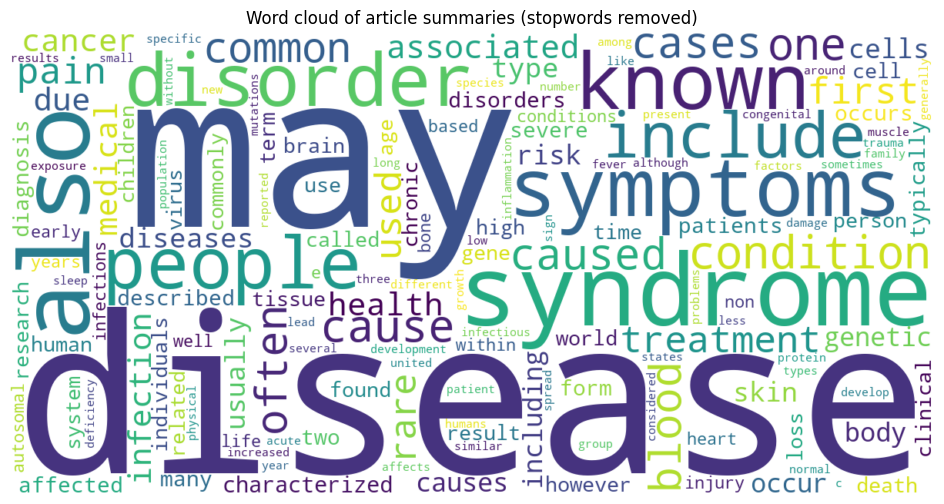

In [7]:
# TODO(human): 4c, chart 1

from collections import Counter

from wordcloud import WordCloud


wc = WordCloud(width=1200, height=600, background_color="white", max_words=150)

words_frequency = Counter(words)

# Remove stopwords so the chart shows meaningful words, not "the", "of", "and".
content_frequency = Counter({word: count for word, count in words_frequency.items() if word not in stop_words})

wc.generate_from_frequencies(content_frequency)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word cloud of article summaries (stopwords removed)")
plt.show()

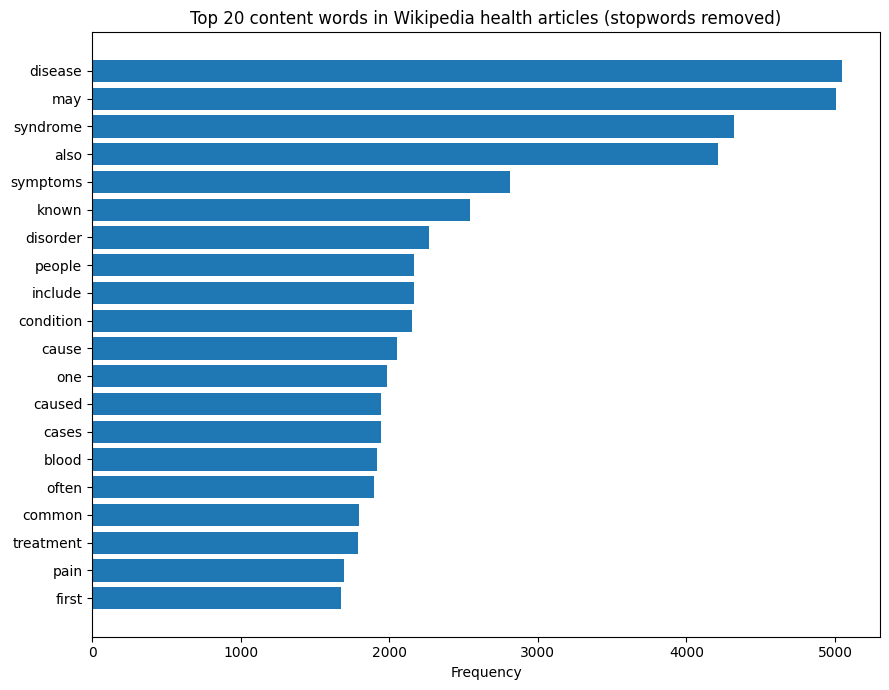

In [8]:
# TODO(human): 4c, chart 2

top_20_words = content_frequency.most_common(20)

labels, values = zip(*top_20_words)

plt.figure(figsize=(9, 7))
plt.barh(labels[::-1], values[::-1])
plt.xlabel("Frequency")
plt.title("Top 20 content words in Wikipedia health articles (stopwords removed)")
plt.tight_layout()
plt.show()

### 4d – Stopwords: total and 10 most frequent

**Stopwords** are very common words that carry little meaning on their own, like `the`, `of`, `and`. Use **NLTK's English stopword list**. NLTK is a popular language-processing library, and the list is already downloaded.

1. **`total_stopwords`**: how many words in `words` are stopwords. Count every occurrence: if `the` appears 3 times, that's 3.
2. **`top_10_stopwords`**: a list of 10 `(word, count)` pairs, most frequent first. Print it.

**Search for:** NLTK stopwords corpus · Python sets and why checking "is X in a set" is much faster than "is X in a list"

**Think:** what **percentage** of all words are stopwords? Compare `top_10_stopwords` with `top_10_words` from 4b. What do you notice?

In [9]:
# TODO(human): 4d
# Define: total_stopwords (int), top_10_stopwords (list of (word, count)), then print both

# stop_words (NLTK's English list) is loaded in the setup cell, because the 4c charts need it too.

total_stopwords = 0

for word in words:
    if word in stop_words:
        total_stopwords += 1


top_10_stopwords = Counter(w for w in words if w in stop_words).most_common(10)

print(f"Total stopwords: {total_stopwords:,} of {len(words):,} words ({total_stopwords / len(words):.1%})")
print("10 most frequent stopwords:")
for word, count in top_10_stopwords:
    print(f"  {word:<10} {count:>7,}")

Total stopwords: 408,716 of 1,035,812 words (39.5%)
10 most frequent stopwords:
  the         56,359
  of          39,883
  and         31,794
  in          26,997
  a           24,567
  is          23,802
  to          20,537
  or          11,410
  as          10,975
  with         9,586


In [10]:
profile_checks.check_4d(total_stopwords, top_10_stopwords)

Step 4d - Stopwords
  ✅ total_stopwords
  ✅ top_10_stopwords
  🎉 All correct!


True

### 4e – Check and identify spelling mistakes

Use the **`pyspellchecker`** library (already installed). It has an English dictionary and reports the words it doesn't know.

1. **`misspelled_words`**: a **set** of the *different* words from `words` that the spell checker doesn't recognize.
   - Tip: check each different word **once**, not all of the ~1 million occurrences. Why is that much faster, and does it change the result?
2. **`top_10_misspelled`**: the 10 most frequent of those words, as `(word, count)` pairs, most frequent first. Print it.
3. For a few of them, print the spell checker's **suggested correction**.

**Search for:** pyspellchecker: finding unknown words · getting a correction or candidates

**Think:** this is the most important question in this step. Look at your top 10: are they *really* spelling mistakes? What kinds of words does a general English dictionary not know? What does that mean for spell-checking *medical* text, and how could you reduce these false alarms?

In [11]:
# TODO(human): 4e
# Define: misspelled_words (set of str), top_10_misspelled (list of (word, count)), then print both

from spellchecker import SpellChecker


spell_checker = SpellChecker()


misspelled_words = spell_checker.unknown(words_frequency)

misspelled_frequency = {}
for k, v in words_frequency.items():
    if k not in misspelled_words:
        continue
    misspelled_frequency[k] = v


top_10_misspelled = Counter(misspelled_frequency).most_common(10)

print(f"Words the spell checker doesn't know: {len(misspelled_words):,} of {len(words_frequency):,} different words")
print("10 most frequent, with the spell checker's suggested correction:")
for word, count in top_10_misspelled:
    print(f"  {word:<14} {count:>5,}  ->  {spell_checker.correction(word)}")

Words the spell checker doesn't know: 17,473 of 42,944 different words
10 most frequent, with the spell checker's suggested correction:
  autosomal        709  ->  autosome
  hiv              274  ->  his
  dna              238  ->  na
  ii               211  ->  i
  covid            165  ->  ovid
  pre              142  ->  are
  uk               124  ->  up
  ft               115  ->  it
  iii              112  ->  wii
  characterised    109  ->  characterized


In [68]:
profile_checks.check_4e(misspelled_words, top_10_misspelled)

Step 4e - Spelling mistakes
  ✅ misspelled_words
  ✅ top_10_misspelled
  🎉 All correct!


True

### Findings

**4a – Splitting into words.** The 7,219 summaries contain **1,035,812 words** (about 144 per summary) and **42,944 different words**. Lowercasing and keeping only the letters a–z makes "The" and "the" the same word, but it also breaks some terms apart: "COVID-19" becomes `covid`, and "Crohn's" becomes `crohn` + `s`.

**4b – Most frequent words.** The top 10 are *the, of, and, in, a, is, to, or, as, with*. **All 10 are stopwords**, and together they make up 24.7% of all words, yet they say nothing about health. Raw word counts are dominated by grammar words, so stopwords have to be removed before the counts become useful.

**4c – Charts.** With stopwords removed, the word cloud and the bar chart clearly show the medical topic: *disease* (5,050 times), *syndrome*, *symptoms*, *disorder*, *condition*, *cause*, *blood*, *treatment*, *pain*. Some general words still rank high (*may*, *also*, *known*, *one*, *often*) because NLTK's list doesn't include them. A custom stopword list for this kind of text would remove them too.

**4d – Stopwords.** **408,716 of the 1,035,812 words are stopwords (39.5%).** The 10 most frequent stopwords are exactly the same as the overall top 10 from 4b. Only 138 of NLTK's 198 stopwords appear in the text at all.

**4e – Spelling mistakes.** The spell checker doesn't recognize **17,473 of the 42,944 different words (40.7%)**, which is 51,985 occurrences (5% of all words). But most of these are **not real mistakes**:
- **Medical terms:** *autosomal* (709 times), *aripiprazole*, *collagenase*
- **Abbreviations:** *hiv*, *dna*, *covid*, *uk*
- **Roman numerals:** *ii*, *iii* (as in "type II diabetes")
- **British spelling:** *characterised*
- **Pieces left by our splitting rule:** *pre* (from words like "pre-eclampsia")

The suggested corrections are often wrong and would damage the text: *hiv → his*, *dna → na*, *covid → ovid*. **A general English dictionary is not suitable for medical text**, and correcting automatically would add errors instead of fixing them. Ways to find the real typos: use a medical dictionary or add known medical terms to the spell checker; ignore abbreviations and very short words; and manually review the rare words. 55.8% of the flagged words appear only once, and that's where real typos are most likely to be.